Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet_img2img.StableDiffusionControlNetImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Saving Screenshot from 2026-10-17 01-01-16.png to Screenshot from 2026-10-17 01-01-16.png


  0%|          | 0/30 [00:00<?, ?it/s]

Faces found: 3


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

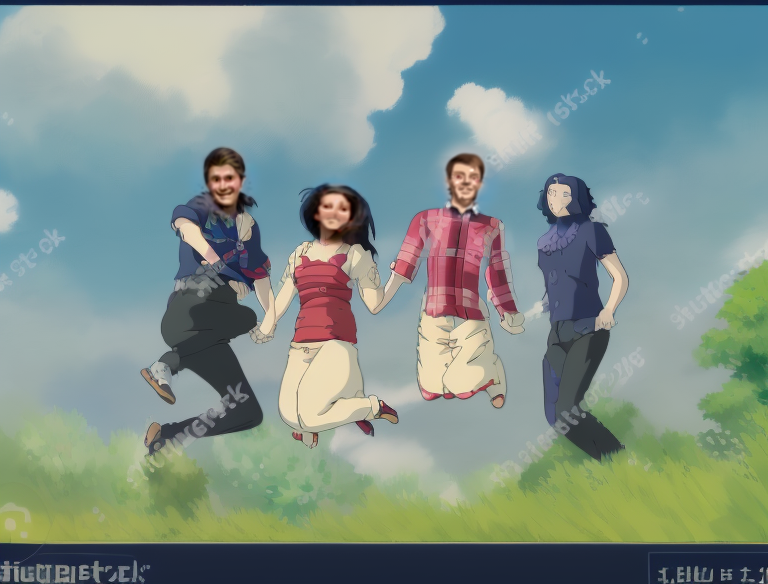

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
!pip install -q diffusers transformers accelerate safetensors opencv-python

import io, cv2, numpy as np, torch
from google.colab import files
from PIL import Image, ImageOps, ImageFilter, ImageDraw
from diffusers import (ControlNetModel, StableDiffusionControlNetImg2ImgPipeline,
                       UniPCMultistepScheduler)

# ---------- 1. Load model (Ghibli-Diffusion + Canny ControlNet) ----------
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_canny", torch_dtype=torch.float16)
pipe2 = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    "nitrosocke/Ghibli-Diffusion", controlnet=controlnet,
    torch_dtype=torch.float16, safety_checker=None).to("cuda")
pipe2.scheduler = UniPCMultistepScheduler.from_config(pipe2.scheduler.config)
pipe2.enable_attention_slicing()

# ---------- 2. Upload photo and resize (longer side 768, divisible by 8) ----------
uploaded = files.upload()
init_image = Image.open(io.BytesIO(next(iter(uploaded.values())))).convert("RGB")
init_image = ImageOps.exif_transpose(init_image)

w, h = init_image.size
scale = 768 / max(w, h)
w, h = int(w * scale) // 8 * 8, int(h * scale) // 8 * 8
init_image = init_image.resize((w, h), Image.LANCZOS)

# ---------- 3. Full-image Ghibli pass (ControlNet keeps the structure) ----------
edges = cv2.Canny(np.array(init_image), 100, 200)
control_image = Image.fromarray(np.stack([edges] * 3, axis=-1))

result = pipe2(
    prompt=("ghibli style, studio ghibli, hayao miyazaki, anime, three people standing together, "
            "clean lineart, smooth cel shading, soft watercolor, detailed faces, "
            "beautiful eyes, vibrant colors, masterpiece, best quality"),
    negative_prompt=("blurry, lowres, deformed face, bad anatomy, extra limbs, bad hands, "
                     "text, watermark, photo, realistic, 3d, noisy, jpeg artifacts"),
    image=init_image,
    control_image=control_image,
    strength=0.75,
    controlnet_conditioning_scale=0.8,
    guidance_scale=7,
    num_inference_steps=40,
    generator=torch.Generator("cuda").manual_seed(7),
).images[0].convert("RGB")

# ---------- 4. Face refinement (blend refined faces back into the Ghibli image) ----------
W, H = init_image.size
result = result.resize((W, H), Image.Resampling.LANCZOS)

gray = cv2.cvtColor(np.array(init_image), cv2.COLOR_RGB2GRAY)
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
faces = cascade.detectMultiScale(gray, scaleFactor=1.08, minNeighbors=5, minSize=(40, 40))
print("Faces found:", len(faces))

face_prompt = (
    "beautiful hand-drawn Japanese animation, Studio Ghibli-inspired aesthetic, "
    "preserve the person's recognizable identity, same face shape, same hairstyle, "
    "same glasses if present, natural anime facial proportions, "
    "expressive warm eyes with clear pupils and highlights, "
    "small naturally drawn nose, subtle friendly smile, "
    "delicate clean line art, soft cel shading, "
    "warm skin tones, cohesive colors, detailed illustration"
)
face_neg = (
    "photorealistic, uncanny face, oversized eyes, cross-eyed, asymmetrical pupils, "
    "distorted mouth, extra teeth, plastic skin, harsh outlines, "
    "blur, duplicate features, deformed glasses"
)

generator = torch.Generator("cuda").manual_seed(21)
refined = result.copy()

for (x, y, fw, fh) in faces:
    # Square crop around the face with some context
    cx, cy = x + fw // 2, y + fh // 2
    side = int(max(fw, fh) * 2.0)
    x0, y0 = max(0, cx - side // 2), max(0, cy - side // 2)
    x1, y1 = min(W, x0 + side), min(H, y0 + side)
    x0, y0 = max(0, x1 - side), max(0, y1 - side)

    crop_orig = init_image.crop((x0, y0, x1, y1))
    cw, ch = crop_orig.size

    # Pad to a square instead of stretching the face
    square = Image.new("RGB", (side, side), (235, 230, 220))
    square.paste(crop_orig, ((side - cw) // 2, (side - ch) // 2))
    square = square.resize((512, 512), Image.Resampling.LANCZOS)

    edges = cv2.Canny(cv2.cvtColor(np.array(square), cv2.COLOR_RGB2GRAY), 70, 150)
    ctrl = Image.fromarray(np.repeat(edges[:, :, None], 3, axis=2))

    face_out = pipe2(
        prompt=face_prompt, negative_prompt=face_neg,
        image=square, control_image=ctrl,
        strength=0.32, controlnet_conditioning_scale=0.60,
        guidance_scale=6.0, num_inference_steps=32,
        generator=generator,
    ).images[0].convert("RGB")

    # Remove padding, restore original crop size
    face_out = face_out.resize((side, side), Image.Resampling.LANCZOS)
    left, top = (side - cw) // 2, (side - ch) // 2
    face_out = face_out.crop((left, top, left + cw, top + ch))

    # Feathered elliptical mask to avoid hard seams
    mask = Image.new("L", (cw, ch), 0)
    ImageDraw.Draw(mask).ellipse(
        (int(cw * 0.18), int(ch * 0.12), int(cw * 0.82), int(ch * 0.88)), fill=255)
    mask = mask.filter(ImageFilter.GaussianBlur(radius=max(4, int(cw * 0.06))))

    base_crop = refined.crop((x0, y0, x1, y1))
    refined.paste(Image.composite(face_out, base_crop, mask), (x0, y0))

# ---------- 5. Save, show, download ----------
refined.save("ghibli_refined.png")
display(refined)
files.download("ghibli_refined.png")